# 최종 탐색 분석 · WSI와 S&P 500 주간 수익률
저장된 수치·그림 검토 전용이다. 전처리·VADER·WSI·FGI를 변경하거나 재실행하지 않는다.
모든 OLS는 설명변수 하나와 절편만 사용한다. 예측·ML·다변량·추가 분석은 수행하지 않는다.

In [1]:
from pathlib import Path
import json,sys
BASE=Path.cwd().resolve()
if not (BASE/"guardian_market_analysis.py").exists():
    BASE=BASE/"midterm paper"
sys.path.insert(0,str(BASE/".packages"))
import pandas as pd
from IPython.display import display,Image,Markdown
RESULTS=BASE/"results/guardian_market_analysis"
FIGURES=BASE/"figures/guardian_market_analysis"
pd.set_option("display.max_colwidth",130)
pd.set_option("display.float_format",lambda x:f"{x:.7g}")
method=json.loads((RESULTS/"market_method.json").read_text(encoding="utf-8"))
print(method["weekly_return"])
print(method["OLS"])

ln(P_w / P_(w-1)); decimal log units
r_(w+h)=alpha+beta*x_w+epsilon, h=0 or 1; separate single predictor plus intercept for every fit


## 1. 출처·가격 검증
FRED SP500 / S&P Dow Jones Indices. 배당 미포함 가격지수이며 별도 수정종가는 없다. 원응답 공휴일 공란과 실제 거래일 누락을 구분한다.

In [2]:
audit=json.loads((RESULTS/"market_daily_audit.json").read_text(encoding="utf-8"))
display(pd.DataFrame([{k:audit[k] for k in ["source","first_available_date","last_available_date","valid_daily_observations",
    "duplicate_dates_in_period_excess","missing_prices_in_validated_dataset","missing_prices_in_period_source_rows",
    "holiday_blank_source_rows","missing_XNYS_session_prices"]}]))
display(pd.read_csv(RESULTS/"sp500_daily_validated.csv").head())
display(pd.read_csv(RESULTS/"market_missing_XNYS_sessions.csv"))

,source,first_available_date,last_available_date,valid_daily_observations,duplicate_dates_in_period_excess,missing_prices_in_validated_dataset,missing_prices_in_period_source_rows,holiday_blank_source_rows,missing_XNYS_session_prices
0,FRED SP500,2017-01-03,2026-10-23,2466,0,0,94,94,0


,date,sp500_close,is_XNYS_session,source,price_basis,week_start
0,2017-01-03,2257.83,True,FRED SP500 / S&P Dow Jones Indices LLC,price_index_close_excluding_dividends,2017-01-02
1,2017-01-04,2270.75,True,FRED SP500 / S&P Dow Jones Indices LLC,price_index_close_excluding_dividends,2017-01-02
2,2017-01-05,2269,True,FRED SP500 / S&P Dow Jones Indices LLC,price_index_close_excluding_dividends,2017-01-02
3,2017-01-06,2276.98,True,FRED SP500 / S&P Dow Jones Indices LLC,price_index_close_excluding_dividends,2017-01-02
4,2017-01-09,2268.9,True,FRED SP500 / S&P Dow Jones Indices LLC,price_index_close_excluding_dividends,2017-01-09


,date,is_XNYS_session,sp500_close,has_valid_close


## 2. 주간 수익률·병합 진단
월~일 마지막 종가의 연속 달력 주 로그비율. 첫 주의 이전 종가와 마지막 주의 다음 수익률은 만들지 않는다. Strict 빈 주도 유지한다.

In [3]:
weekly=pd.read_csv(RESULTS/"sp500_weekly_returns.csv",float_precision="round_trip")
display(weekly.head(8))
display(pd.read_csv(RESULTS/"market_merge_diagnostics.csv"))

,week_start,week_id,week_end,days_observed,is_complete_week,weekly_close,last_price_date,first_price_date,price_observation_count,expected_XNYS_sessions,expected_last_session,missing_session_prices,last_price_matches_expected_last_session,previous_week_close,previous_price_date,weekly_log_return,return_price_span_calendar_days,missing_return_reason,price_basis
0,2016-12-26,2016-W52,2017-01-01,1,False,NaN,NaN,NaN,0,0,NaN,0,False,NaN,NaN,NaN,NaN,no_current_week_close,price_index_close_excluding_dividends
1,2017-01-02,2017-W01,2017-01-08,7,True,2276.98,2017-01-06,2017-01-03,4,4,2017-01-06,0,True,NaN,NaN,NaN,NaN,no_previous_calendar_week_close,price_index_close_excluding_dividends
2,2017-01-09,2017-W02,2017-01-15,7,True,2274.64,2017-01-13,2017-01-09,5,5,2017-01-13,0,True,2276.98,2017-01-06,-0.001028205,7,NaN,price_index_close_excluding_dividends
3,2017-01-16,2017-W03,2017-01-22,7,True,2271.31,2017-01-20,2017-01-17,4,4,2017-01-20,0,True,2274.64,2017-01-13,-0.001465041,7,NaN,price_index_close_excluding_dividends
4,2017-01-23,2017-W04,2017-01-29,7,True,2294.69,2017-01-27,2017-01-23,5,5,2017-01-27,0,True,2271.31,2017-01-20,0.010241,7,NaN,price_index_close_excluding_dividends
5,2017-01-30,2017-W05,2017-02-05,7,True,2297.42,2017-02-03,2017-01-30,5,5,2017-02-03,0,True,2294.69,2017-01-27,0.001188996,7,NaN,price_index_close_excluding_dividends
6,2017-02-06,2017-W06,2017-02-12,7,True,2316.1,2017-02-10,2017-02-06,5,5,2017-02-10,0,True,2297.42,2017-02-03,0.008097982,7,NaN,price_index_close_excluding_dividends
7,2017-02-13,2017-W07,2017-02-19,7,True,2351.16,2017-02-17,2017-02-13,5,5,2017-02-17,0,True,2316.1,2017-02-10,0.01502409,7,NaN,price_index_close_excluding_dividends


,predictor,role,relationship,return_variable,calendar_complete_weeks,valid_predictor_weeks,valid_return_weeks,valid_paired_weeks,predictor_only_weeks,return_only_weeks,neither_valid_weeks,first_matched_predictor_week,last_matched_predictor_week,first_matched_return_week,last_matched_return_week
0,broad_WSI_count,primary,contemporaneous,weekly_log_return,512,512,511,511,1,0,0,2017-01-09,2026-10-19,2017-01-09,2026-10-19
1,broad_WSI_count,primary,exploratory_next_week,next_week_log_return,512,512,511,511,1,0,0,2017-01-02,2026-10-12,2017-01-09,2026-10-19
2,broad_WSI_continuous,continuous_robustness,contemporaneous,weekly_log_return,512,512,511,511,1,0,0,2017-01-09,2026-10-19,2017-01-09,2026-10-19
3,broad_WSI_continuous,continuous_robustness,exploratory_next_week,next_week_log_return,512,512,511,511,1,0,0,2017-01-02,2026-10-12,2017-01-09,2026-10-19
4,strict_WSI_count,strict_robustness,contemporaneous,weekly_log_return,512,504,511,503,1,8,0,2017-01-09,2026-10-19,2017-01-09,2026-10-19
5,strict_WSI_count,strict_robustness,exploratory_next_week,next_week_log_return,512,504,511,503,1,8,0,2017-01-02,2026-10-12,2017-01-09,2026-10-19
6,strict_WSI_continuous,strict_continuous_robustness,contemporaneous,weekly_log_return,512,504,511,503,1,8,0,2017-01-09,2026-10-19,2017-01-09,2026-10-19
7,strict_WSI_continuous,strict_continuous_robustness,exploratory_next_week,next_week_log_return,512,504,511,503,1,8,0,2017-01-02,2026-10-12,2017-01-09,2026-10-19
8,FGI_weekly_mean,FGI_context_benchmark,contemporaneous,weekly_log_return,512,508,511,507,1,4,0,2017-01-09,2026-10-19,2017-01-09,2026-10-19
9,FGI_weekly_mean,FGI_context_benchmark,exploratory_next_week,next_week_log_return,512,508,511,507,1,4,0,2017-01-02,2026-10-12,2017-01-09,2026-10-19


## 3. 동시점 상관·OLS
수익률은 소수 로그 단위, beta는 지수 1포인트당 수익률이다. 표준오차·t·p는 conventional OLS이며 자기상관·이분산에 강건하지 않다.

,predictor,role,relationship,return_variable,n_pairs,pearson,spearman
0,broad_WSI_count,primary,contemporaneous,weekly_log_return,511,0.1773379,0.1466998
2,broad_WSI_continuous,continuous_robustness,contemporaneous,weekly_log_return,511,0.2083721,0.1788712
4,strict_WSI_count,strict_robustness,contemporaneous,weekly_log_return,503,0.18355,0.1724186
6,strict_WSI_continuous,strict_continuous_robustness,contemporaneous,weekly_log_return,503,0.1997655,0.1961231
8,FGI_weekly_mean,FGI_context_benchmark,contemporaneous,weekly_log_return,507,0.1880219,0.1709214


,predictor,role,relationship,return_variable,n_observations,alpha,beta,se_beta,t_beta,p_value_beta_two_sided,R_squared,adjusted_R_squared,residual_df,residual_sigma,standard_error_type
0,broad_WSI_count,primary,contemporaneous,weekly_log_return,511,-0.008185427,0.0002327561,5.725349e-05,4.065362,5.555081e-05,0.03144874,0.02954589,509,0.02364443,conventional OLS iid; not HAC/heteroskedasticity robust
2,broad_WSI_continuous,continuous_robustness,contemporaneous,weekly_log_return,511,-0.02001297,0.0004835859,0.0001006088,4.806595,2.023844e-06,0.04341893,0.0415396,509,0.02349787,conventional OLS iid; not HAC/heteroskedasticity robust
4,strict_WSI_count,strict_robustness,contemporaneous,weekly_log_return,503,-0.005005055,0.0001684031,4.029349e-05,4.179412,3.449004e-05,0.03369061,0.03176185,501,0.02376794,conventional OLS iid; not HAC/heteroskedasticity robust
6,strict_WSI_continuous,strict_continuous_robustness,contemporaneous,weekly_log_return,503,-0.0125413,0.0003270241,7.166338e-05,4.563336,6.340341e-06,0.03990624,0.03798989,501,0.02369138,conventional OLS iid; not HAC/heteroskedasticity robust
8,FGI_weekly_mean,FGI_context_benchmark,contemporaneous,weekly_log_return,507,-0.008868477,0.0002318594,5.389581e-05,4.301993,2.032971e-05,0.03535223,0.03344204,505,0.0234773,conventional OLS iid; not HAC/heteroskedasticity robust


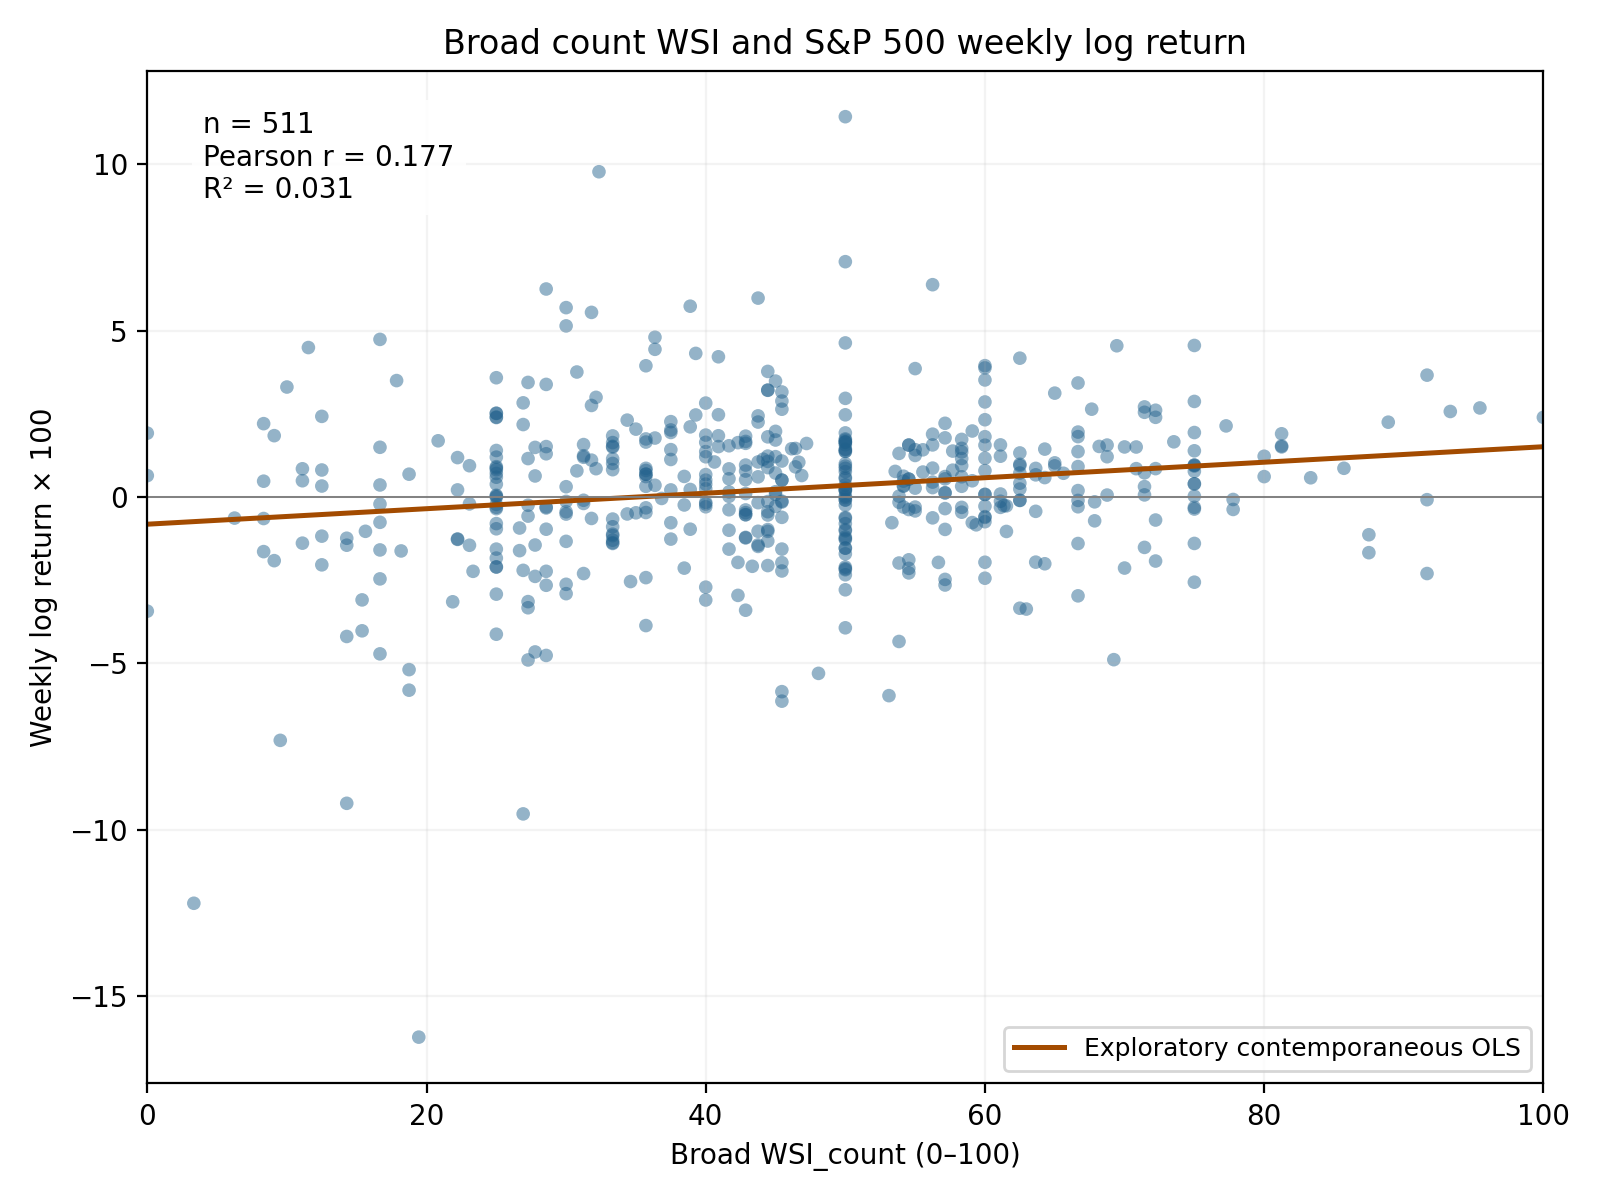

In [4]:
corr=pd.read_csv(RESULTS/"market_correlations.csv",float_precision="round_trip")
ols=pd.read_csv(RESULTS/"market_OLS_results.csv",float_precision="round_trip")
display(corr.loc[corr.relationship.eq("contemporaneous")])
display(ols.loc[ols.relationship.eq("contemporaneous")])
display(Image(filename=str(FIGURES/"market_broad_count_scatter.png"),width=1000))

## 4. 탐색적 다음 주 관계·FGI 맥락 비교
WSI_w와 r_(w+1)을 정확한 다음 달력 주로 연결한다. 예측 모형이나 예측 능력의 증거로 부르지 않는다. FGI는 정답이 아니며 각 명세의 n이 다를 수 있다.

In [5]:
display(corr.loc[corr.relationship.eq("exploratory_next_week")])
display(ols.loc[ols.relationship.eq("exploratory_next_week")])
display(pd.read_csv(RESULTS/"market_benchmark_comparison.csv",float_precision="round_trip"))

,predictor,role,relationship,return_variable,n_pairs,pearson,spearman
1,broad_WSI_count,primary,exploratory_next_week,next_week_log_return,511,-0.01093186,-0.04889375
3,broad_WSI_continuous,continuous_robustness,exploratory_next_week,next_week_log_return,511,-0.01055181,-0.03796855
5,strict_WSI_count,strict_robustness,exploratory_next_week,next_week_log_return,503,-0.009004833,-0.03354711
7,strict_WSI_continuous,strict_continuous_robustness,exploratory_next_week,next_week_log_return,503,-0.0208366,-0.04295452
9,FGI_weekly_mean,FGI_context_benchmark,exploratory_next_week,next_week_log_return,507,-0.0428334,-0.06591152


,predictor,role,relationship,return_variable,n_observations,alpha,beta,se_beta,t_beta,p_value_beta_two_sided,R_squared,adjusted_R_squared,residual_df,residual_sigma,standard_error_type
1,broad_WSI_count,primary,exploratory_next_week,next_week_log_return,511,0.003014294,-1.430177e-05,5.798439e-05,-0.2466487,0.8052796,0.0001195055,-0.001844896,509,0.0240238,conventional OLS iid; not HAC/heteroskedasticity robust
3,broad_WSI_continuous,continuous_robustness,exploratory_next_week,next_week_log_return,511,0.003495647,-2.44045e-05,0.0001025085,-0.238073,0.8119203,0.0001113407,-0.001853077,509,0.02402389,conventional OLS iid; not HAC/heteroskedasticity robust
5,strict_WSI_count,strict_robustness,exploratory_next_week,next_week_log_return,503,0.002663217,-8.225117e-06,4.080656e-05,-0.2015636,0.8403397,8.108702e-05,-0.001914759,501,0.02407969,conventional OLS iid; not HAC/heteroskedasticity robust
7,strict_WSI_continuous,strict_continuous_robustness,exploratory_next_week,next_week_log_return,503,0.003848683,-3.392433e-05,7.27229e-05,-0.4664876,0.6410693,0.0004341641,-0.001560977,501,0.02407544,conventional OLS iid; not HAC/heteroskedasticity robust
9,FGI_weekly_mean,FGI_context_benchmark,exploratory_next_week,next_week_log_return,507,0.004881556,-5.306513e-05,5.507851e-05,-0.9634452,0.3357852,0.0018347,-0.0001418646,505,0.02398108,conventional OLS iid; not HAC/heteroskedasticity robust


,predictor,role,relationship,return_variable,n_pairs,pearson,spearman,alpha,beta,p_value_beta_two_sided,R_squared
0,broad_WSI_count,primary,contemporaneous,weekly_log_return,511,0.1773379,0.1466998,-0.008185427,0.0002327561,5.555081e-05,0.03144874
1,broad_WSI_count,primary,exploratory_next_week,next_week_log_return,511,-0.01093186,-0.04889375,0.003014294,-1.430177e-05,0.8052796,0.0001195055
2,broad_WSI_continuous,continuous_robustness,contemporaneous,weekly_log_return,511,0.2083721,0.1788712,-0.02001297,0.0004835859,2.023844e-06,0.04341893
3,broad_WSI_continuous,continuous_robustness,exploratory_next_week,next_week_log_return,511,-0.01055181,-0.03796855,0.003495647,-2.44045e-05,0.8119203,0.0001113407
4,FGI_weekly_mean,FGI_context_benchmark,contemporaneous,weekly_log_return,507,0.1880219,0.1709214,-0.008868477,0.0002318594,2.032971e-05,0.03535223
5,FGI_weekly_mean,FGI_context_benchmark,exploratory_next_week,next_week_log_return,507,-0.0428334,-0.06591152,0.004881556,-5.306513e-05,0.3357852,0.0018347


## 5. 수익률·표준화 WSI 시계열
단위를 분리한 두 패널이다. 수익률은 그림에서만 100배, WSI 표준화는 동시점 유효 쌍의 표본 표준편차(ddof=1)를 사용한다.

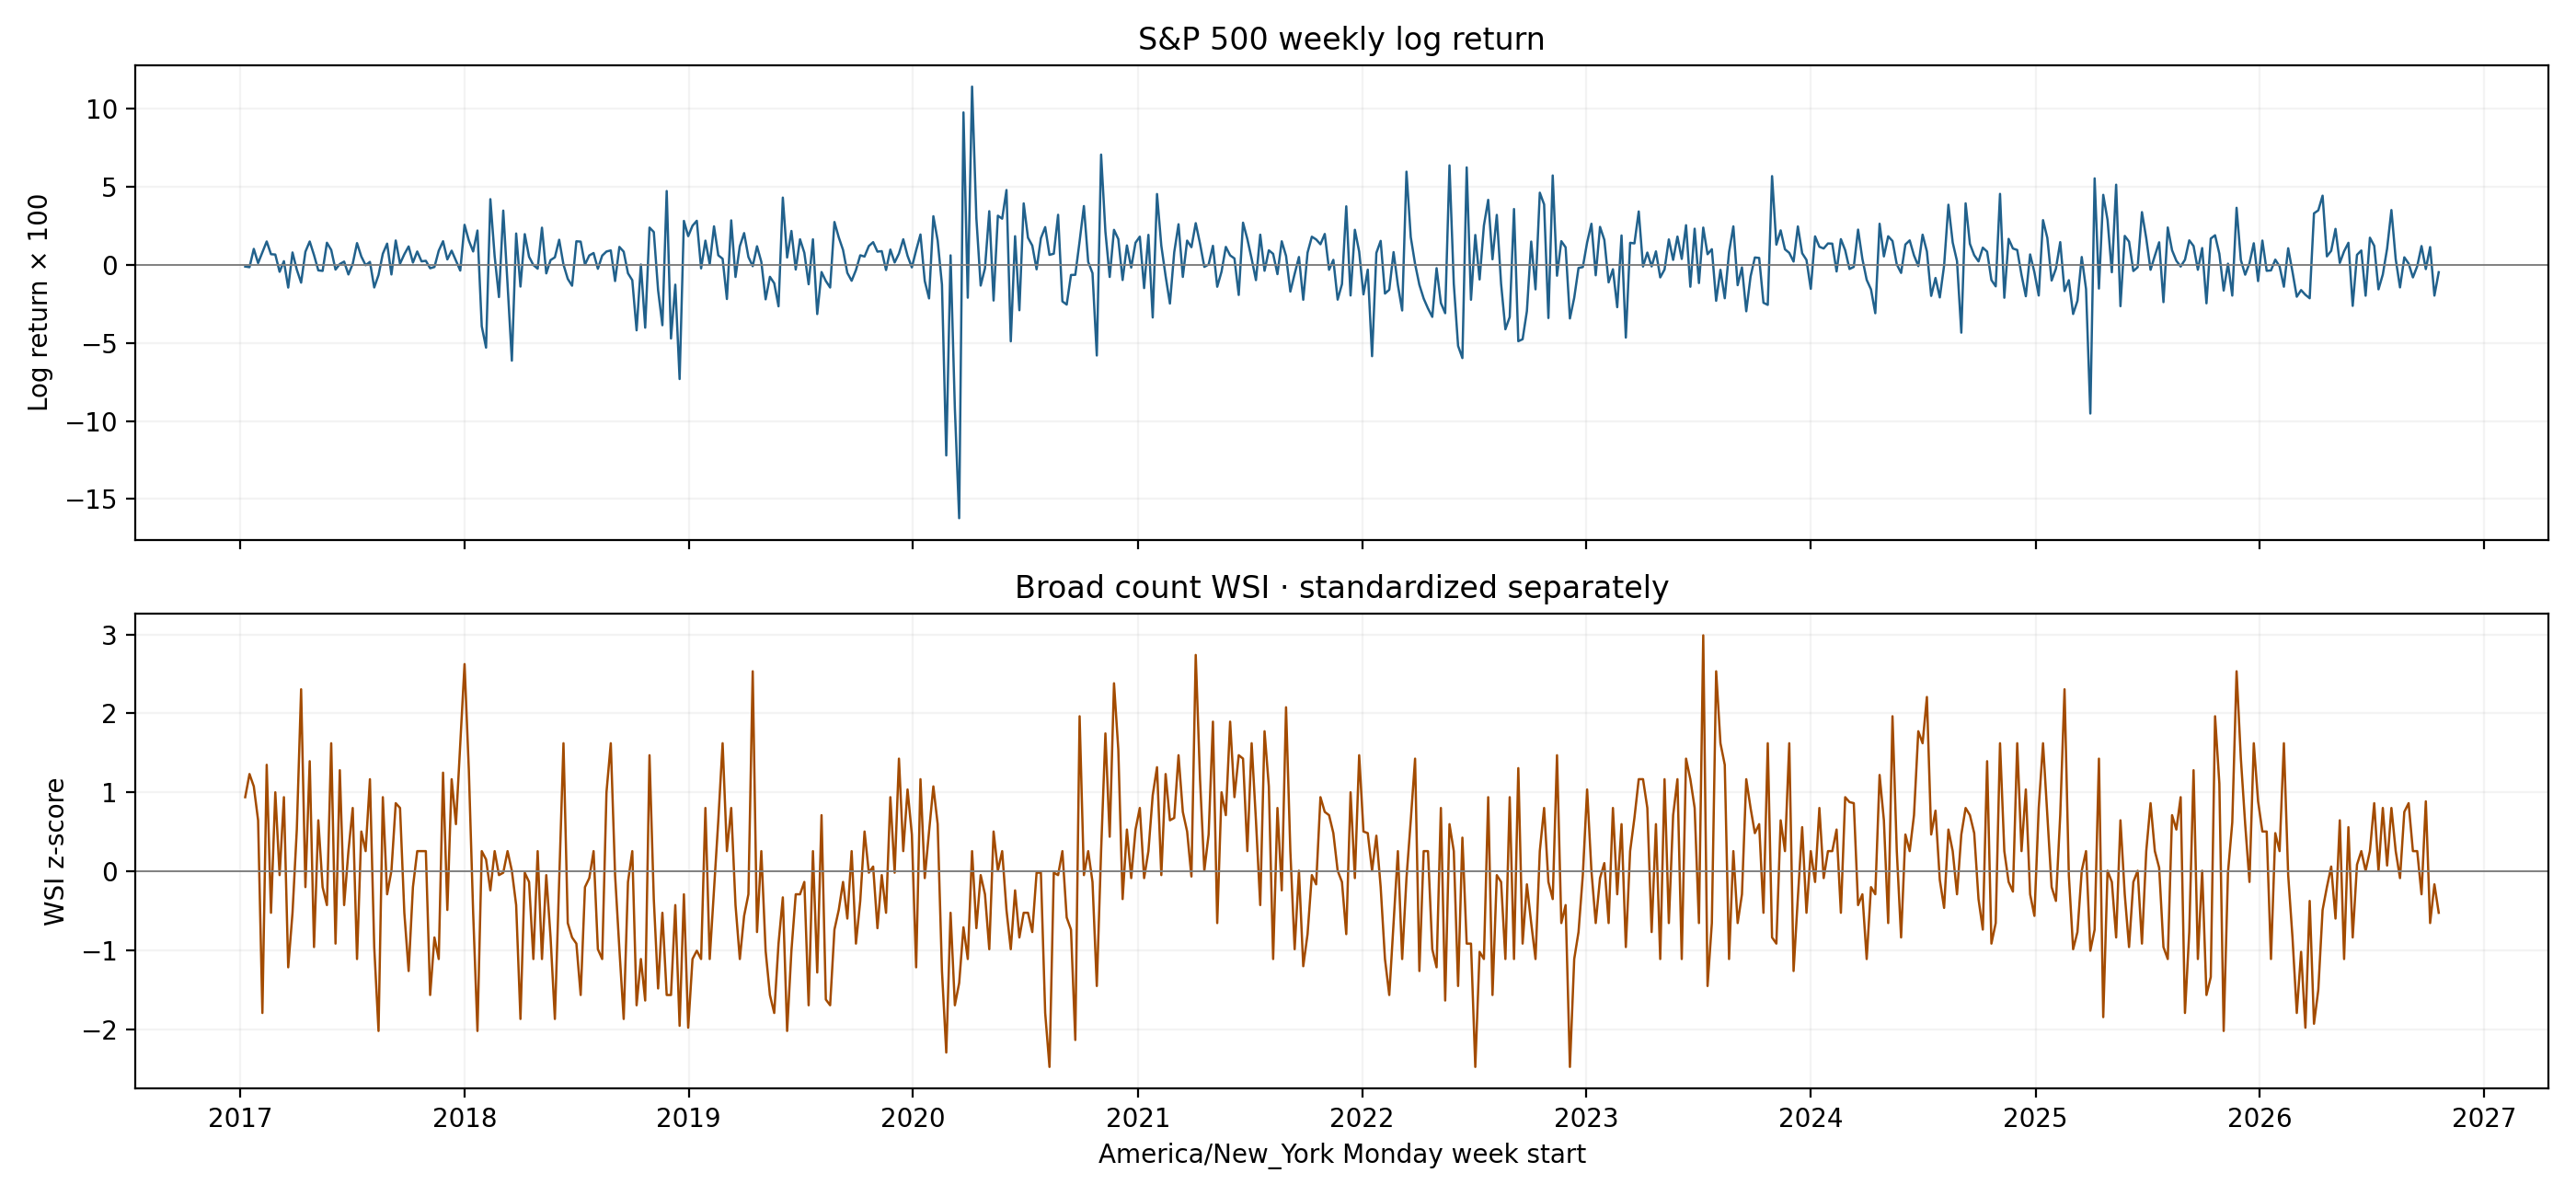

,series,standardization_sample,n,mean,std_ddof1
0,broad_WSI_count,contemporaneous matched complete weeks,511,45.32736,18.28698


In [6]:
display(Image(filename=str(FIGURES/"market_weekly_returns_wsi.png"),width=1250))
display(pd.read_csv(RESULTS/"market_plot_standardization.csv"))

## 6. 독립 검증·기술 인계
기존 자료·결과 해시, 원응답 가격, 주간 수식·다음 주 정렬, 모든 단변량 OLS와 상관을 확인한다. 추가 분석은 수행하지 않는다.

In [7]:
print((RESULTS/"independent_validation.json").read_text(encoding="utf-8"))
display(Markdown((BASE/"GUARDIAN_MARKET_HANDOFF.md").read_text(encoding="utf-8")))

{
  "status": "passed",
  "daily_prices_verified_against_raw_FRED": 2466,
  "daily_duplicates": 0,
  "missing_XNYS_prices": 0,
  "weekly_calendar_rows": 513,
  "weekly_returns_verified": 511,
  "last_prices_and_consecutive_week_log_formula_independently_verified": true,
  "no_fill_and_no_gap_skipping_synthetic_tests": "passed",
  "next_week_date_alignment_verified": true,
  "original_WSI_and_FGI_values_and_missingness_exactly_preserved": true,
  "univariate_OLS_models_verified_against_SciPy": 10,
  "correlation_rows_verified_against_SciPy": 10,
  "conventional_SE_t_p_R2_adjusted_R2_verified": true,
  "p_values_also_verified_via_incomplete_beta_function": true,
  "merge_diagnostics_and_benchmark_comparison_verified": true,
  "figures_verified": 4,
  "all_upstream_file_hashes_unchanged": true,
  "forecasting_ML_multivariate_or_additional_models": false
}



# 최종 탐색 분석 · 기술 인계

## 데이터 출처

- FRED `SP500`, 원출처 S&P Dow Jones Indices LLC: [자료 설명](https://fred.stlouisfed.org/series/SP500).
- 다운로드: https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500; 원응답 SHA-256 `269b80fef05c69061cb7f9c42ac6f12c03b3a1074e21da3c64b501036c7a8193`.
- 일별 종가 가격지수. 배당 포함 총수익지수가 아니며 별도 adjusted close 필드는 없다. 임의 수정종가를 만들지 않았다.
- FRED 기본 공개 CSV를 보관하고 2017-01-01~2026-10-25를 로컬 선택했다. 다른 가격 출처를 이어 붙이지 않았다.

## 방법·수식

- 뉴욕 월요일~일요일 달력 유지. 분석은 완전한 주만 사용하며, 부분 경계 주는 파일에 유지한다.
- P_w = 주 안의 마지막 유효 거래일 종가; r_w = ln(P_w/P_(w-1)). 단위는 소수 로그수익률이다.
- 직전 **달력 주** 종가가 없으면 수익률은 NA. 기간 밖 초기 가격·보간·전방 채움은 사용하지 않는다.
- 동시점: r_w = alpha + beta*x_w + epsilon_w. 탐색적 다음 주: r_(w+1) = alpha + beta*x_w + epsilon_w.
- 다음 주는 정확한 week_start+7일로 연결하고 그 후 결측 쌍을 제외한다. 각 적합은 설명변수 하나와 절편만 사용한다.
- x는 broad/strict count·continuous WSI 또는 맥락 비교 FGI_weekly_mean. 기존 값·생성 규칙은 변경하지 않는다.
- SE(beta)=sqrt([SSE/(n-2)]/Sxx); t=beta/SE(beta); p=2*t_df=n-2.sf(|t|). 모두 conventional OLS 기준이다.
- R²=1-SSE/SST; adjusted R²=1-(1-R²)*(n-1)/(n-2). beta는 지수 1포인트당 소수 로그수익률이다.
- Pearson 및 동률 평균 순위 Spearman을 각 명세의 유효 쌍에서 계산한다. CSV round_trip 정밀도를 사용한다.
- 그림만 수익률에 100을 곱한다. 시계열 WSI z=(x-mean)/std(ddof=1), 동시점 유효 쌍 표본 기준이다.

## 사용 패키지

- requests 2.34.2; pandas 2.3.3; numpy 2.2.5; pyarrow 25.0.1; scipy 1.15.3; matplotlib 3.10.9; exchange_calendars 4.13.2.
- 노트북: nbformat, nbclient, ipykernel, jupyter_client, IPython. 검증 이미지 읽기: Pillow.
- 표준 라이브러리: pathlib, hashlib, json, datetime, sys, importlib.metadata; 검증용 statistics/math.
- 통계 함수 근거: [SciPy 단순 선형 적합](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.linregress.html).

## 표본 크기·자료 진단

- 유효 일별 종가 2,466개; 2017-01-03~2026-10-23.
- 기간 내 날짜 중복 0; 유효 가격 자료의 결측 0.
- 원응답의 기간 내 행 2,560개 중 가격 공란 94개 (비거래일 공란 94). 예상 XNYS 거래일 2,466일; 누락 거래일 가격 0개.
- 달력 513주, 완전한 주 512주. 첫 완전 주는 기간 내 직전 주 종가가 없어 수익률이 결측이다.

| predictor | relationship | valid_paired_weeks | predictor_only_weeks | return_only_weeks | first_matched_predictor_week | last_matched_predictor_week |
| --- | --- | --- | --- | --- | --- | --- |
| broad_WSI_count | contemporaneous | 511 | 1 | 0 | 2017-01-09 | 2026-10-19 |
| broad_WSI_count | exploratory_next_week | 511 | 1 | 0 | 2017-01-02 | 2026-10-12 |
| broad_WSI_continuous | contemporaneous | 511 | 1 | 0 | 2017-01-09 | 2026-10-19 |
| broad_WSI_continuous | exploratory_next_week | 511 | 1 | 0 | 2017-01-02 | 2026-10-12 |
| strict_WSI_count | contemporaneous | 503 | 1 | 8 | 2017-01-09 | 2026-10-19 |
| strict_WSI_count | exploratory_next_week | 503 | 1 | 8 | 2017-01-02 | 2026-10-12 |
| strict_WSI_continuous | contemporaneous | 503 | 1 | 8 | 2017-01-09 | 2026-10-19 |
| strict_WSI_continuous | exploratory_next_week | 503 | 1 | 8 | 2017-01-02 | 2026-10-12 |
| FGI_weekly_mean | contemporaneous | 507 | 1 | 4 | 2017-01-09 | 2026-10-19 |
| FGI_weekly_mean | exploratory_next_week | 507 | 1 | 4 | 2017-01-02 | 2026-10-12 |

## 수치 결과

| predictor | relationship | n_pairs | pearson | spearman |
| --- | --- | --- | --- | --- |
| broad_WSI_count | contemporaneous | 511 | 0.1773379 | 0.1466998 |
| broad_WSI_count | exploratory_next_week | 511 | -0.01093186 | -0.04889375 |
| broad_WSI_continuous | contemporaneous | 511 | 0.2083721 | 0.1788712 |
| broad_WSI_continuous | exploratory_next_week | 511 | -0.01055181 | -0.03796855 |
| strict_WSI_count | contemporaneous | 503 | 0.18355 | 0.1724186 |
| strict_WSI_count | exploratory_next_week | 503 | -0.009004833 | -0.03354711 |
| strict_WSI_continuous | contemporaneous | 503 | 0.1997655 | 0.1961231 |
| strict_WSI_continuous | exploratory_next_week | 503 | -0.0208366 | -0.04295452 |
| FGI_weekly_mean | contemporaneous | 507 | 0.1880219 | 0.1709214 |
| FGI_weekly_mean | exploratory_next_week | 507 | -0.0428334 | -0.06591152 |

| predictor | relationship | n_observations | alpha | beta | se_beta | t_beta | p_value_beta_two_sided | R_squared | adjusted_R_squared |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| broad_WSI_count | contemporaneous | 511 | -0.008185427 | 0.0002327561 | 5.725349e-05 | 4.065362 | 5.555081e-05 | 0.03144874 | 0.02954589 |
| broad_WSI_count | exploratory_next_week | 511 | 0.003014294 | -1.430177e-05 | 5.798439e-05 | -0.2466487 | 0.8052796 | 0.0001195055 | -0.001844896 |
| broad_WSI_continuous | contemporaneous | 511 | -0.02001297 | 0.0004835859 | 0.0001006088 | 4.806595 | 2.023844e-06 | 0.04341893 | 0.0415396 |
| broad_WSI_continuous | exploratory_next_week | 511 | 0.003495647 | -2.44045e-05 | 0.0001025085 | -0.238073 | 0.8119203 | 0.0001113407 | -0.001853077 |
| strict_WSI_count | contemporaneous | 503 | -0.005005055 | 0.0001684031 | 4.029349e-05 | 4.179412 | 3.449004e-05 | 0.03369061 | 0.03176185 |
| strict_WSI_count | exploratory_next_week | 503 | 0.002663217 | -8.225117e-06 | 4.080656e-05 | -0.2015636 | 0.8403397 | 8.108702e-05 | -0.001914759 |
| strict_WSI_continuous | contemporaneous | 503 | -0.0125413 | 0.0003270241 | 7.166338e-05 | 4.563336 | 6.340341e-06 | 0.03990624 | 0.03798989 |
| strict_WSI_continuous | exploratory_next_week | 503 | 0.003848683 | -3.392433e-05 | 7.27229e-05 | -0.4664876 | 0.6410693 | 0.0004341641 | -0.001560977 |
| FGI_weekly_mean | contemporaneous | 507 | -0.008868477 | 0.0002318594 | 5.389581e-05 | 4.301993 | 2.032971e-05 | 0.03535223 | 0.03344204 |
| FGI_weekly_mean | exploratory_next_week | 507 | 0.004881556 | -5.306513e-05 | 5.507851e-05 | -0.9634452 | 0.3357852 | 0.0018347 | -0.0001418646 |

### Broad·FGI 비교표

| predictor | relationship | n_pairs | pearson | spearman | beta | p_value_beta_two_sided | R_squared |
| --- | --- | --- | --- | --- | --- | --- | --- |
| broad_WSI_count | contemporaneous | 511 | 0.1773379 | 0.1466998 | 0.0002327561 | 5.555081e-05 | 0.03144874 |
| broad_WSI_count | exploratory_next_week | 511 | -0.01093186 | -0.04889375 | -1.430177e-05 | 0.8052796 | 0.0001195055 |
| broad_WSI_continuous | contemporaneous | 511 | 0.2083721 | 0.1788712 | 0.0004835859 | 2.023844e-06 | 0.04341893 |
| broad_WSI_continuous | exploratory_next_week | 511 | -0.01055181 | -0.03796855 | -2.44045e-05 | 0.8119203 | 0.0001113407 |
| FGI_weekly_mean | contemporaneous | 507 | 0.1880219 | 0.1709214 | 0.0002318594 | 2.032971e-05 | 0.03535223 |
| FGI_weekly_mean | exploratory_next_week | 507 | -0.0428334 | -0.06591152 | -5.306513e-05 | 0.3357852 | 0.0018347 |

## 생성 파일

- `data/raw/market/fred_sp500_2017-01-01_2026-10-25.csv`, `.metadata.json`, `source_access_log.json`: 원응답·출처·접근 기록.
- `results/guardian_market_analysis/sp500_daily_validated.{csv,parquet}`: 유효 일별 종가.
- `results/guardian_market_analysis/sp500_weekly_returns.{csv,parquet}`: 주간 종가·로그수익률·관측 수.
- `results/guardian_market_analysis/merged_market_WSI_weekly.{csv,parquet}`: 분리된 WSI 열·FGI·동시/다음 주 수익률.
- `market_correlations.csv`, `market_OLS_results.csv`, `market_benchmark_comparison.csv`: 상관·OLS·맥락 비교.
- `market_merge_diagnostics.csv`, `market_pair_status.csv`: 유효/비매칭 표본과 날짜.
- `market_daily_audit.json`, `market_calendar_audit.csv`, `market_missing_source_rows.csv`, `market_missing_XNYS_sessions.csv`: 자료 진단.
- `market_timeseries_plot_data.csv`, `market_plot_standardization.csv`: 그림 자료와 표준화 기준.
- `market_method.json`, `validation_summary.json`, `independent_validation.json`: 방법·패키지·입력 해시·독립 검증.
- 위 확장자 없는 결과 파일명 기준 폴더: `results/guardian_market_analysis/`.
- `figures/guardian_market_analysis/market_broad_count_scatter.png`.
- `figures/guardian_market_analysis/market_broad_count_scatter.svg`.
- `figures/guardian_market_analysis/market_weekly_returns_wsi.png`.
- `figures/guardian_market_analysis/market_weekly_returns_wsi.svg`.
- `guardian_market_analysis_review.ipynb`: 실행된 저장 결과 검토 노트북.
- 코드: `guardian_market_data.py`, `guardian_market_analysis.py`, `guardian_market_stats.py`, `guardian_market_outputs.py`, `verify_guardian_market_analysis.py`, `build_guardian_market_notebook.py`.

## 한계·주의

- 탐색적 동시점/다음 주 연관성만 계산했다. 인과·예측 능력·거래 수익성·시장 효율성 위반의 증거가 아니다.
- Conventional 표준오차·p값은 자기상관·이분산에 강건하지 않다. 여러 명세를 비교했으며 다중검정 보정은 하지 않았다.
- 통계적 유의성과 경제적 중요성은 같지 않다. 작은 R²를 예측력으로 해석하지 않는다.
- WSI 측정오차·기사 밀도 차이·두 전략의 중첩이 있다. FGI는 정답이 아니며 기존 자료 계보·누락을 유지했다.
- 모델마다 결측 제거 후 표본 날짜·수가 다를 수 있다. 위 비교표는 공통 표본으로 강제하지 않았으며 n을 병기했다.
- 가격지수 수익률은 배당 재투자를 포함하지 않는다. 원자료 재배포 조건은 FRED 출처 페이지를 확인한다.
- 전처리·VADER·WSI·FGI 자료와 이전 결과를 수정하지 않았다. 예측·ML·다변량·추가 모형은 수행하지 않았다.
